# Conditional displacement with a fixed sideband

The spacing comparison targets **the same CD beta=1 gate** at a fixed total
duration per curve, on all qubit g/e × Fock n=0..8 inputs. A separate
strength comparison allows weaker coupling a longer gate. The signed-beta
scaling section explicitly varies the target. No curve intentionally changes
the operation by under-displacing when coupling becomes weaker.

The verified reference gives **370 ns and 99.2278% coherent gate fidelity**.
Its sideband phase and plateau amplitude remain fixed. Every qubit pi pulse
is 30 ns, and only the outer sideband ramps change amplitude, for 5 ns each.
Peak coupling respects the **200 ns minimum vacuum-swap time**.

New mixed-axis, fractional-angle and timing designs were tested. None has yet
passed 99% in less time. The reference is the fastest verified result in this
finite study, not a global optimum. The calculations below explain what
different cancellation strategies remove and why their native fidelity matters.

The model is a perfect two-level qubit with resonant JC, no loss or static chi.
The qubit drive must be calibrated at the chosen **steady pump-on frequency**.
The ideal model does not predict an unknown device-dependent frequency shift
during turn-on/off.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from project_paths import ROOT
import cd_trains as cd
import hardware_check as hw
from notebook_figures import read,certificate,drives,finish,waveform_figure,individual_overlaps,DATA

ref=certificate('cd_constant_reference')
display(pd.DataFrame([{k:ref[k] for k in ['command_us','fidelity','worst_basis_fidelity','peak_swap_ns','levels']}]))
print('Independent replay:',ref['columns'],'input columns;',ref['complex_amplitudes'],
      'complex amplitudes; max difference',ref['independent_max_difference'])


,command_us,fidelity,worst_basis_fidelity,peak_swap_ns,levels
0,0.37,0.992278,0.979996,281.332152,96


Independent replay: 18 input columns; 3456 complex amplitudes; max difference 1.0339757656912846e-25


## Pulse spacing at fixed beta and fixed total duration

Here the center-to-center spacing is $\Delta=30\,\mathrm{ns}+t_{\rm idle}$.
The physical pi envelope stays30ns. More repetitions of the same X,X,−X,−X
cycle fill a fixed-duration window as spacing decreases. Each curve has
exactly the same total duration, including the two5ns sideband ramps.

The intended gate remains beta=1 on all 18 inputs. One constant coupling is
normalized from the wanted **first Magnus coefficient of the actual packed
and RFDC-filtered waveform**. Pulse phases are not refitted and fidelity is
not optimized. DAC resolution leaves less than0.3% coefficient mismatch.
The earlier reference table uses its separately calibrated coupling; this
spacing sweep deliberately uses the same leading-generator normalization
throughout each fixed-duration curve.

The middle panel separates the wanted coefficient from the achieved vacuum
mean. Errors in the achieved operation remain in the fidelity; they do not
redefine the target. The right panel confirms that changing pulse density
does not covertly change the CD sideband strength within a duration group.
The direction to the right is decreasing spacing;30 ns is the hardware floor.

At370ns the spacings90,45,30 ns give77.4136%,97.4220%,99.1035%. At730ns,
the30ns point gives99.9149%. These compare fixed targets and durations,
unlike a sweep that simply shortens the gate as more pulses are removed.
The [complete data](../runs/pulse_spacing/summary.json) and
[example timing table](../runs/pulse_spacing/cd_T370_N12_pulses.csv) are saved.

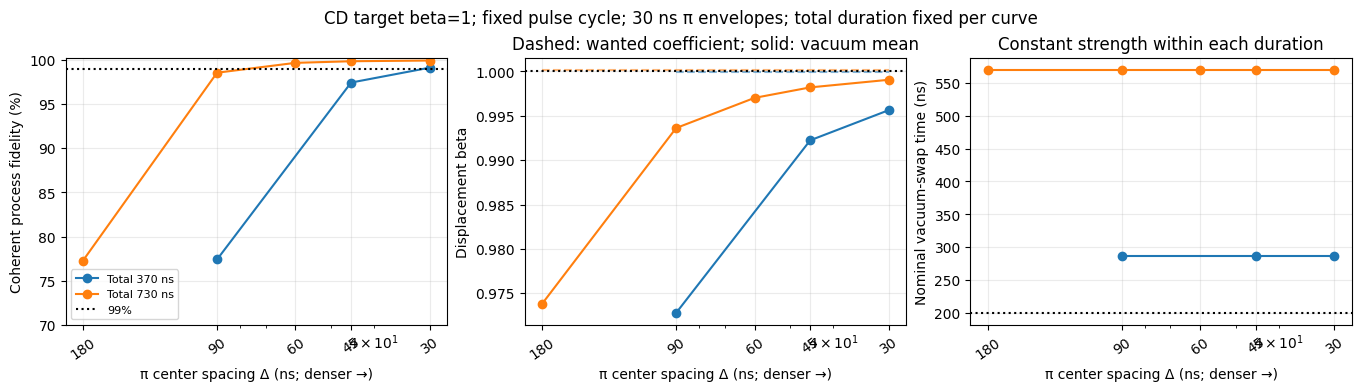

,duration_us,cells,spacing_ns,gap_ns,nominal_swap_ns,wanted_coefficient_actual,vacuum_displacement_real,levels,process_fidelity_percent
0,0.37,4,90.0,60.0,286.670330,0.999919,0.972793,64,77.413553
1,0.37,8,45.0,15.0,286.670330,0.999919,0.992242,64,97.421987
2,0.37,12,30.0,0.0,286.670330,0.999919,0.995637,64,99.103474
3,0.73,4,180.0,150.0,569.413668,1.000150,0.973815,64,77.285797
4,0.73,8,90.0,60.0,569.413668,1.000150,0.993627,64,98.535092
5,0.73,12,60.0,30.0,569.413668,1.000150,0.997025,64,99.652168
6,0.73,16,45.0,15.0,569.413668,1.000150,0.998206,64,99.833944
7,0.73,24,30.0,0.0,569.413668,1.000150,0.999062,64,99.914945


CD SPACING CHECK:8 points;144 input columns; 18432 independent complex amplitudes;fixed duration per curve;no phase/fidelity fit


In [2]:

from pulse_spacing_figures import cd_figure,load as spacing_data
spacing_report,spacing_rows=spacing_data()
display(cd_figure().assign(process_fidelity_percent=lambda r:100*r.fidelity).drop(columns='fidelity'))
cd_spacing=spacing_rows[spacing_rows.gate=='cd']
assert len(cd_spacing)==8 and sum(cd_spacing.columns=='fidelity')==1
print('CD SPACING CHECK:8 points;144 input columns;',int(cd_spacing.independent_amplitudes.sum()),
      'independent complex amplitudes;fixed duration per curve;no phase/fidelity fit')


## 1. Fixed beta, weaker sideband, longer gate

The word **X, X, −X, −X** repeats K times. These are qubit pi pulses with
physical DAC axes 0,0,180,180 degrees. The pump has one fixed quadrature.

For each K, one **constant coupling** is calibrated against the same beta=1
target. Quibit phases are unchanged. A rough area rule is

$$\beta\simeq\frac g2(0.120K+0.005\,\mu\mathrm{s}),\qquad
t_{\rm swap}=\frac{\pi}{2g},\qquad T=0.120K+0.010\,\mu\mathrm{s}.$$

The small strength correction is determined by complete quantum propagation;
the target is never redefined from the achieved output. The left plot shows
the coherent gate fidelity and the weakest basis-input fidelity. The right
plot shows the duration used at the same strength. Thus these are comparisons
of the same intended operation, not weaker displacements.

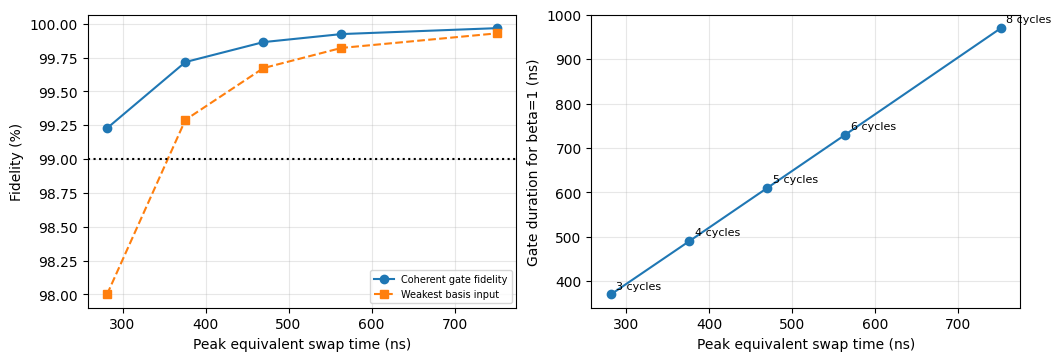

,repeats,nominal_swap_ns,command_time_us,fidelity,worst_basis_fidelity
0,3,283.180847,0.37,0.992277,0.979996
1,4,378.237550,0.49,0.997167,0.992896
2,5,472.950348,0.61,0.998641,0.996722
3,6,567.639934,0.73,0.999234,0.998211
4,8,756.404683,0.97,0.999673,0.999289


Strength comparison: 5 gates; 90 input columns; 11520 independent amplitudes


In [3]:

strengths=read('runs/reference_strengths/summary.json')
rows=pd.DataFrame(strengths['results'])
assert len(rows)==5 and all(rows.strength==1) and rows.columns.nunique()>0
fig,axes=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
axes[0].plot(rows.peak_swap_ns,100*rows.fidelity,'o-',label='Coherent gate fidelity')
axes[0].plot(rows.peak_swap_ns,100*rows.worst_basis_fidelity,'s--',label='Weakest basis input')
axes[0].axhline(99,c='k',ls=':');axes[0].set(xlabel='Peak equivalent swap time (ns)',ylabel='Fidelity (%)')
axes[0].legend(fontsize=7)
axes[1].plot(rows.peak_swap_ns,1000*rows.command_time_us,'o-')
for _,r in rows.iterrows():axes[1].annotate(f"{int(r.repeats)} cycles",(r.peak_swap_ns,1000*r.command_time_us),xytext=(4,4),textcoords='offset points',fontsize=8)
axes[1].set(xlabel='Peak equivalent swap time (ns)',ylabel='Gate duration for beta=1 (ns)')
for ax in axes:ax.grid(alpha=.3)
finish('cd_fixed_beta_strength_and_time')
display(rows[['repeats','nominal_swap_ns','command_time_us','fidelity','worst_basis_fidelity']])
print('Strength comparison:',strengths['recipes_compared'],'gates;',strengths['target_input_columns_compared'],
      'input columns;',strengths['independent_amplitudes_compared'],'independent amplitudes')


## 1b. A reusable recipe for smaller and larger displacements

Let $b=|\beta|$. Repeat the same four-pulse word K times; change only one
constant sideband strength for the whole gate. The checked empirical rule is

$$K=\left\lceil\max(2.5b,2.25b^2)\right\rceil,\qquad
L=0.120K+0.005\;\mu\mathrm{s},$$

$$g_0=2b/L,\qquad g=g_0(1+c g_0^2),\qquad
c=0.0004071933463\;\mu\mathrm{s}^2.$$

For positive beta use pump phase270 degrees; negative beta adds180 degrees.
The qubit axes remain0,0,180,180 degrees and each physical envelope stays30ns.
This is a calibrated scaling law, not a theorem or an optimizer rerun at every
beta. The single coefficient c comes from beta=1. All 20 listed signed targets
were independently checked on all 18 inputs with automatic cutoff growth.
The lowest checked process fidelity is99.1038%. Arbitrary interpolated beta
still needs the full simulation; do not extrapolate a guaranteed 99% bound.

Here different beta values deliberately correspond to different target gates.
This scaling plot is separate from the fixed-beta strength comparison above.

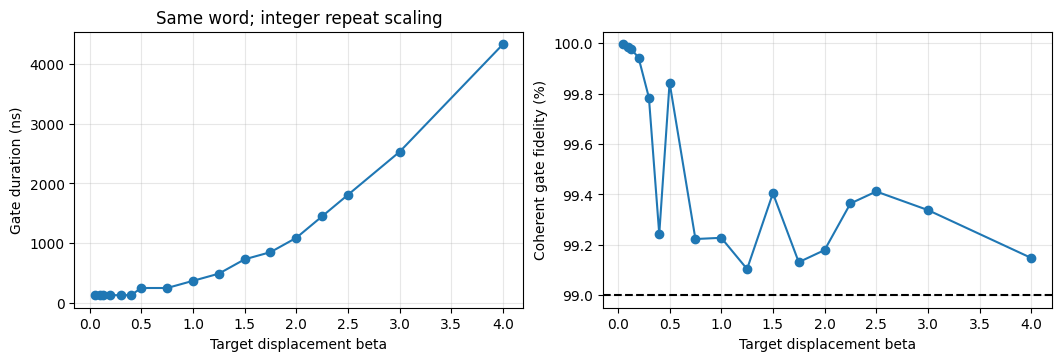

,beta,cycles,duration_ns,nominal_swap_ns,fidelity
2,-2.000,9,1090.0,423.733444,0.991791
1,-1.000,3,370.0,283.207905,0.992278
0,-0.500,2,250.0,382.252006,0.998440
3,0.050,1,130.0,1962.983848,0.999965
4,0.100,1,130.0,980.725381,0.999865
5,0.125,1,130.0,784.121008,0.999792
6,0.200,1,130.0,488.835574,0.999427
7,0.300,1,130.0,324.207605,0.997843
8,0.400,1,130.0,241.410527,0.992426
9,0.500,2,250.0,382.252006,0.998440


SCALING CHECK:20 signed targets;360 input columns; 71424 independently compared amplitudes


In [4]:

rule=read('runs/constant_pump_gaussian/binary_rule_summary.json')
manifest=read('runs/constant_pump_gaussian/verified/manifest.json')
names={r['job']['name'] for r in rule['results']}
checked=[r for r in manifest['results'] if r['name'] in names]
assert len(checked)==20 and sum(r['columns'] for r in checked)==360
assert min(r['fidelity'] for r in checked)>.99
assert all(r['pump_phase_constant'] and r['equivalent_swap_ns']>=200 for r in checked)
assert max(r['independent_max_difference'] for r in checked)<1e-10
scaling=pd.DataFrame([dict(beta=r['job']['strength'],cycles=r['job']['cycles'],
    duration_ns=r['command_us']*1000,nominal_swap_ns=r['job']['swap']*1000,
    fidelity=r['fidelity']) for r in rule['results']]).sort_values('beta')
positive=scaling[scaling.beta>0]
fig,axes=plt.subplots(1,2,figsize=(10.5,3.5),constrained_layout=True)
axes[0].plot(positive.beta,positive.duration_ns,'o-')
axes[0].set(xlabel='Target displacement beta',ylabel='Gate duration (ns)',title='Same word; integer repeat scaling')
axes[1].plot(positive.beta,100*positive.fidelity,'o-');axes[1].axhline(99,c='k',ls='--')
axes[1].set(xlabel='Target displacement beta',ylabel='Coherent gate fidelity (%)')
for ax in axes:ax.grid(alpha=.3)
finish('cd_signed_beta_scaling');display(scaling)
print('SCALING CHECK:20 signed targets;360 input columns;',
      sum(r['complex_amplitudes'] for r in checked),'independently compared amplitudes')


## 2. Which terms need cancellation?

At the CD pump quadrature,

$$H_{\rm JC}=\tfrac g2(\sigma_xP-\sigma_yX),\quad
X=a+a^\dagger,\quad P=i(a^\dagger-a).$$

Following the finite qubit drive defines a rotation angle theta(t). Its
toggling-frame Hamiltonian contains the wanted force plus transverse terms:

$$H_I=\tfrac g2\sigma_xP-\tfrac g2
[\sigma_y\cos\theta(t)-\sigma_z\sin\theta(t)]X.$$

First-order transverse cancellation requires the angular-path centroid
$\int e^{i\theta(t)}dt$ to vanish. A phase label alone does not establish this.
The plot shows the centroid path and the positive functional that enters a
surviving longitudinal cubic error. For controls about X only, that principal
cubic coefficient is proportional to

$$-\tfrac14\int_0^T\left|\int_0^t e^{i\theta(s)}ds\right|^2dt.$$

Its sign cannot be reversed by another X twirl. Timing can reduce it, but
mixed-axis trajectories or a genuinely different signed composition are needed
to cancel it. This is a statement about that perturbative coefficient, not a
global fidelity bound. Native coefficients independently match the functional
to 8.5e−21. Instantaneous X and −X toggle JC identically; their benefit here is
**finite-pulse error cancellation**, not a claimed higher Trotter order.

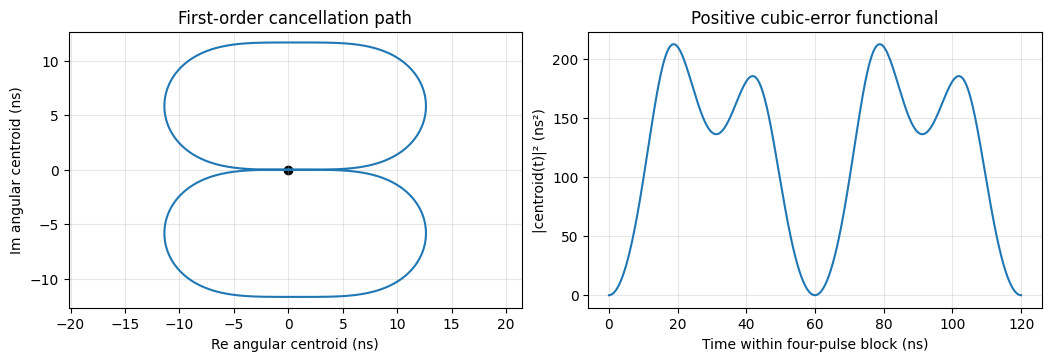

,word,first_transverse_integral_abs,integral_abs_F_squared_us3,predicted_sigma_x_Weyl_XP2_coefficient_us3,native_coefficient_us3,coefficient_error,coefficient_comparisons,conclusion
0,"[X, X, -X, -X, X, X, -X, -X]",8.155994e-17,0.000029,-0.000007,-0.000007,8.470329e-21,2,The longitudinal principal cubic coefficient i...


In [5]:

# One finite four-pulse block; an explanatory qubit trajectory, not a fidelity score.
substeps=32;dt=cd.DT/substeps
q=np.repeat(np.r_[cd.pi_samples(),cd.pi_samples(),-cd.pi_samples(),-cd.pi_samples()],substeps)
theta=2*(np.cumsum(q)*dt-q*dt/2)
centroid=np.cumsum(np.exp(1j*theta))*dt
fig,axes=plt.subplots(1,2,figsize=(10.4,3.5),constrained_layout=True)
axes[0].plot(centroid.real*1000,centroid.imag*1000);axes[0].scatter([0],[0],c='k')
axes[0].set(xlabel='Re angular centroid (ns)',ylabel='Im angular centroid (ns)',title='First-order cancellation path')
axes[0].axis('equal')
axes[1].plot(np.arange(len(q))*dt*1000,abs(centroid)**2*1e6)
axes[1].set(xlabel='Time within four-pulse block (ns)',ylabel='|centroid(t)|² (ns²)',title='Positive cubic-error functional')
for ax in axes:ax.grid(alpha=.3)
finish('cd_magnus_geometry')
display(pd.DataFrame([read('runs/independent_review/same_axis_cubic.json')]))


## 3. Strategic alternatives were judged by full gate fidelity

The ten-pulse X-twirl construction has the correct first average, but leaves
second-order conditional number and squeezing terms. A separate strategy
uses a path followed by its inverse to make the actual toggling Hamiltonian
time symmetric and remove its second Magnus term. It then adjusts pi/N
rotations, qubit axes and physical dwells to cancel the first-force centroid.

Both exported examples below have the same beta=1 target and a fixed pump.
They were independently replayed through SDK words, RFDC and converged
oscillator cutoffs. They fail 99% and are not recommended. A canonical
fourth-order signed-JC composition also has a967.6 ns time floor in this hardware
model, so formal order alone does not make it competitive.

Time symmetry must be checked on the complete waveform, including its ramps,
padding and sample origin. An isolated flat-window Hann word can leave a
second-order term. A new direct quantum check of the complete370ns reference,
including its ramps, instead gives $\|\Omega_2/g^2\|=5.44\times10^{-16}$.
Thus this complete gate already cancels second order. Its unwanted first-order
ramp contribution and cubic/higher errors remain. Details and counted searches are in the
[CD research report](../runs/strategic_cd/README.md).

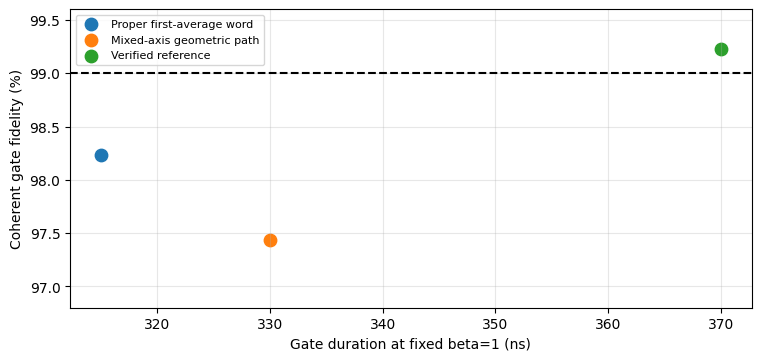

,name,command_us,fidelity,worst_basis_fidelity,accepted
0,best_proper10,0.315,0.982371,0.950497,False
1,best_mixed_geometric,0.330,0.974377,0.926294,False
2,cd_constant_reference,0.370,0.992278,0.979996,True


In [6]:

comparison=[certificate(n) for n in ['best_proper10','best_mixed_geometric','cd_constant_reference']]
labels=['Proper first-average word','Mixed-axis geometric path','Verified reference']
fig,ax=plt.subplots(figsize=(7.5,3.5),constrained_layout=True)
for label,r in zip(labels,comparison):ax.scatter(r['command_us']*1000,100*r['fidelity'],s=80,label=label)
ax.axhline(99,c='k',ls='--');ax.set(xlabel='Gate duration at fixed beta=1 (ns)',ylabel='Coherent gate fidelity (%)',ylim=(96.8,99.6))
ax.grid(alpha=.3);ax.legend(fontsize=8);finish('cd_strategies_native_decision')
display(pd.DataFrame([{k:r[k] for k in ['name','command_us','fidelity','worst_basis_fidelity','accepted']} for r in comparison]))


## 4. Literal reference sequence and constant pump

Play twelve30ns pi pulses with axes **0,0,180,180 degrees repeated three
times**. Use a constant sideband plateau with nominal swap283.21 ns and fixed
phase270degrees, with one5ns turn-on and one5ns turn-off. The qubit train begins
after the initial ramp. No internal pump modulation or final qubit Rz is used.

The [complete pulse table](../runs/research_verified/cd_constant_reference_pulses.csv)
and [exact SDK words](../runs/research_verified/cd_constant_reference_words.npz)
give the complete recipe. The plot aligns the common digital-filter delay for
display; full filtered shapes are propagated. Magnitude is shown separately
for both channels.

,pulse,start_ns,duration_ns,rotation_pi_units,qubit_DAC_deg,reversed_envelope
0,1,5.0,30.0,1.0,0.0,False
1,2,35.0,30.0,1.0,0.0,False
2,3,65.0,30.0,1.0,180.0,False
3,4,95.0,30.0,1.0,180.0,False
4,5,125.0,30.0,1.0,0.0,False
5,6,155.0,30.0,1.0,0.0,False
6,7,185.0,30.0,1.0,180.0,False
7,8,215.0,30.0,1.0,180.0,False
8,9,245.0,30.0,1.0,0.0,False
9,10,275.0,30.0,1.0,0.0,False


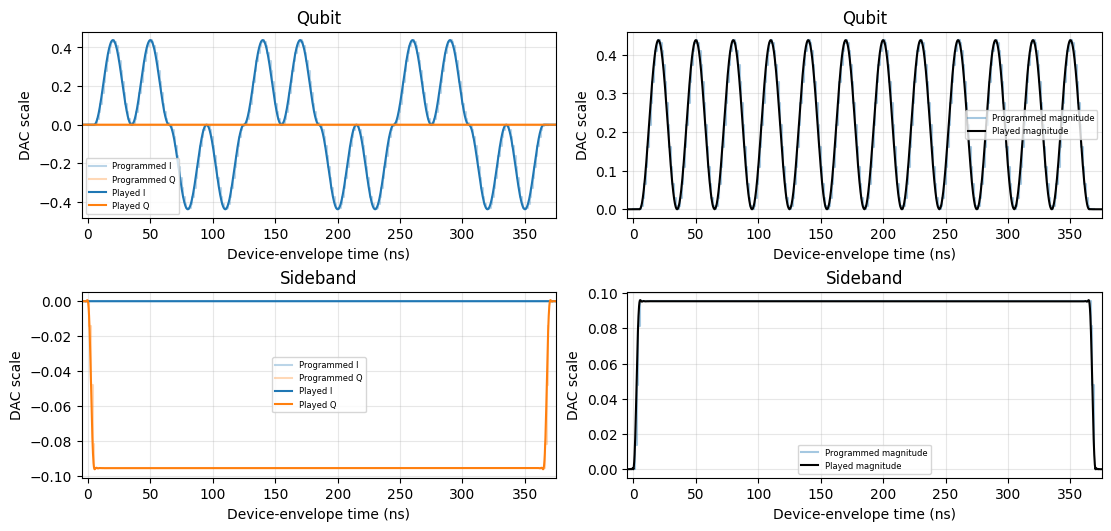

In [7]:

display(pd.read_csv(DATA/'cd_constant_reference_pulses.csv'))
waveform_figure('cd_constant_reference');finish('cd_constant_pump_IQ')


## 5. Fresh independent replay on all 18 inputs

The acceptance score is $|\operatorname{Tr}(T^\dagger V)|^2/18^2$, where T and V
are exact and simulated output columns. Relative phases and leakage remain.
The individual-state plot is diagnostic; it does not replace this coherent
metric. In particular,99% process fidelity does not imply 99% for every basis
input. This cell independently evolves all 18 columns at a larger cutoff.

FRESH CD CHECK:18columns; 4608 amplitudes;maxdifference 1.0339757656912846e-25 F 0.9922779449668537


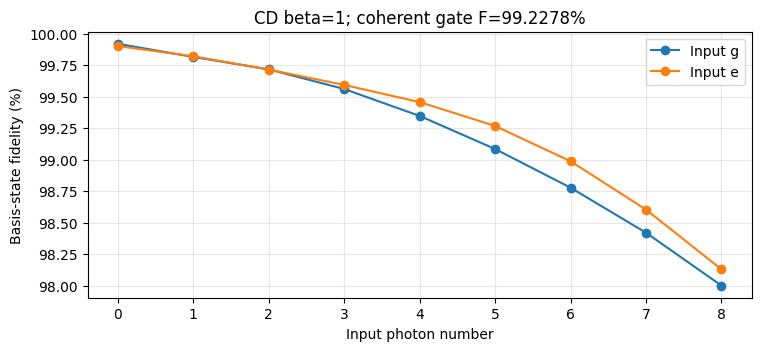

In [8]:

q,s,qf,sf,words=drives('cd_constant_reference')
space=cd.Space(128,9);initial=np.eye(256,dtype=complex)[:,space.inputs]
V=hw.propagate(qf,sf,initial,cd.DT/8,order=16);T=cd.target_columns(space,'cd',1.)
saved=np.load(DATA/'cd_constant_reference_columns.npz')['output'];pad=np.zeros_like(V);pad[:len(saved)]=saved
error=float(np.max(abs(V-pad)));F=float(abs(np.vdot(T,V)/18)**2)
assert V.shape==(256,18) and error<1e-10 and F>.99
print('FRESH CD CHECK:18columns;',V.size,'amplitudes;maxdifference',error,'F',F)
overlap=np.sum(T.conj()*V,axis=0)
fig,ax=plt.subplots(figsize=(7.5,3.4),constrained_layout=True)
for offset,label in [(0,'Input g'),(9,'Input e')]:ax.plot(np.arange(9),100*abs(overlap[offset:offset+9])**2,'o-',label=label)
ax.set(xlabel='Input photon number',ylabel='Basis-state fidelity (%)',title=f'CD beta=1; coherent gate F={100*F:.4f}%')
ax.grid(alpha=.3);ax.legend();finish('cd_all_input_diagnostics')
